### Prerequisites

Run this notebook from the repository root using the project environment.
Generate the shared CelebA feature caches by running
`explore_celeba.ipynb` and sections 2.4–2.9 of `erm_celeba.ipynb`.

Cached features and model checkpoints are excluded from Git.
Running this notebook regenerates random selections and checkpoints.
Local experiments used PyTorch 2.11.0+cu128 on an RTX 4070 Laptop GPU.

# Random Filtering on CelebA

Uniformly remove training examples without replacement at rates matched
to gradient-based filtering, then retrain a linear classifier.

## 1. Setup and Cached Features

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch

SEEDS = [42, 123, 2026]
FILTER_RATES = [0.05, 0.10, 0.20]
FEATURE_DIR = Path("data/processed/features")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Reuse shared features; keep the test set for final evaluation.
X_train = np.load(FEATURE_DIR / "train_features.npy", mmap_mode="r")
y_train = np.load(FEATURE_DIR / "train_labels.npy")
groups_train = np.load(FEATURE_DIR / "train_groups.npy")

X_val = np.load(FEATURE_DIR / "val_features.npy", mmap_mode="r")
y_val = np.load(FEATURE_DIR / "val_labels.npy")
groups_val = np.load(FEATURE_DIR / "val_groups.npy")

for split, X, y, groups, expected_size in [
    ("train", X_train, y_train, groups_train, 162770),
    ("val", X_val, y_val, groups_val, 19867),
]:
    assert X.shape == (expected_size, 512)
    assert y.shape == groups.shape == (expected_size,)
    assert np.isin(y, [0, 1]).all()
    assert np.isin(groups, [0, 1, 2, 3]).all()
    assert np.array_equal(groups // 2, y)
    assert np.isfinite(X).all()
    print(f"{split}: features={X.shape}, labels={y.shape}")

group_counts = pd.DataFrame({
    "Group": range(4),
    "Train": np.bincount(groups_train, minlength=4),
    "Validation": np.bincount(groups_val, minlength=4),
})

print("\nGroup counts:")
print(group_counts.to_string(index=False))
print("\nSetup completed successfully!")

Device: cuda
train: features=(162770, 512), labels=(162770,)
val: features=(19867, 512), labels=(19867,)

Group counts:
 Group  Train  Validation
     0  71629        8535
     1  66874        8276
     2  22880        2874
     3   1387         182

Setup completed successfully!


## 2. Random Selection and Group Retention

Use the same removal counts and selection seeds as the EPIC notebook.
Group labels are used only to analyze retention.

In [2]:
SELECTION_DIR = Path("data/processed/random_filtering")
METRICS_DIR = Path("results/metrics")
SELECTION_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

n_train = len(y_train)
all_indices = np.arange(n_train)
original_counts = np.bincount(groups_train, minlength=4)

keep_indices = {}
selection_records = []
retention_records = []

for rate in FILTER_RATES:
    rate_pct = int(round(rate * 100))
    n_remove = round(rate * n_train)

    for selection_seed in SEEDS:
        rng = np.random.default_rng(selection_seed)
        removed = rng.choice(n_train, size=n_remove, replace=False)
        kept = np.setdiff1d(all_indices, removed)

        assert len(np.unique(removed)) == n_remove
        assert len(kept) == n_train - n_remove
        assert np.intersect1d(removed, kept).size == 0

        keep_indices[(rate_pct, selection_seed)] = kept

        # Save exact selections for reproducibility.
        np.savez(
            SELECTION_DIR / f"random_{rate_pct}pct_seed{selection_seed}.npz",
            removed=removed,
            kept=kept,
        )

        selection_records.append({
            "Filter Rate (%)": rate_pct,
            "Selection Seed": selection_seed,
            "Original": n_train,
            "Removed": len(removed),
            "Retained": len(kept),
        })

        removed_counts = np.bincount(groups_train[removed], minlength=4)

        for g in range(4):
            original = int(original_counts[g])
            removed_count = int(removed_counts[g])

            retention_records.append({
                "Filter Rate (%)": rate_pct,
                "Selection Seed": selection_seed,
                "Group": g,
                "Original": original,
                "Removed": removed_count,
                "Retained": original - removed_count,
                "Retention Rate (%)": 100 * (original - removed_count) / original,
            })

selection_df = pd.DataFrame(selection_records)
retention_df = pd.DataFrame(retention_records)

selection_df.to_csv(
    METRICS_DIR / "random_filtering_selections.csv", index=False
)
retention_df.to_csv(
    METRICS_DIR / "random_filtering_group_retention.csv", index=False
)

print("Selection summary:")
print(selection_df.to_string(index=False))

print("\nGroup retention for selection seed 42:")
print(
    retention_df[retention_df["Selection Seed"] == 42]
    .round(2)
    .to_string(index=False)
)

print("\nRandom selections saved successfully!")

Selection summary:
 Filter Rate (%)  Selection Seed  Original  Removed  Retained
               5              42    162770     8138    154632
               5             123    162770     8138    154632
               5            2026    162770     8138    154632
              10              42    162770    16277    146493
              10             123    162770    16277    146493
              10            2026    162770    16277    146493
              20              42    162770    32554    130216
              20             123    162770    32554    130216
              20            2026    162770    32554    130216

Group retention for selection seed 42:
 Filter Rate (%)  Selection Seed  Group  Original  Removed  Retained  Retention Rate (%)
               5              42      0     71629     3584     68045               95.00
               5              42      1     66874     3351     63523               94.99
               5              42      2     22880     

## 3. Classifier Training and Validation

Train a fresh linear classifier on retained features.
Select the checkpoint with minimum validation loss.

In [4]:
import copy
import time
from torch.utils.data import DataLoader, TensorDataset

EPOCHS = 20
BATCH_SIZE = 512
LR = 1e-3
WEIGHT_DECAY = 1e-4

MODEL_DIR = Path("results/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

val_dataset = TensorDataset(
    torch.from_numpy(np.array(X_val, copy=True)),
    torch.from_numpy(y_val.copy()).long(),
)
val_loader = DataLoader(
    val_dataset, batch_size=1024, shuffle=False
)
criterion = torch.nn.CrossEntropyLoss()


def evaluate_classifier(model):
    model.eval()
    loss_sum = 0.0
    predictions = []

    with torch.inference_mode():
        for features, labels in val_loader:
            features = features.to(device)
            labels = labels.to(device)
            logits = model(features)

            loss_sum += criterion(logits, labels).item() * len(labels)
            predictions.append(logits.argmax(1).cpu().numpy())

    predictions = np.concatenate(predictions)
    correct = predictions == y_val
    group_acc = {
        g: float(correct[groups_val == g].mean() * 100)
        for g in range(4)
    }

    return {
        "val_loss": loss_sum / len(y_val),
        "overall": float(correct.mean() * 100),
        "worst_group": min(group_acc.values()),
        "group_accuracies": group_acc,
    }


def train_random_classifier(indices, rate_pct, selection_seed, train_seed):
    torch.manual_seed(train_seed)
    np.random.seed(train_seed)

    model = torch.nn.Linear(512, 2).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
    )

    dataset = TensorDataset(
        torch.from_numpy(np.array(X_train[indices], copy=True)),
        torch.from_numpy(y_train[indices].copy()).long(),
    )
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(train_seed),
        num_workers=0,
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    history = []

    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_loss_sum = 0.0

        for features, labels in loader:
            features = features.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            loss = criterion(model(features), labels)
            loss.backward()
            optimizer.step()
            train_loss_sum += loss.item() * len(labels)

        metrics = evaluate_classifier(model)
        train_loss = train_loss_sum / len(dataset)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": metrics["val_loss"],
            "val_accuracy": metrics["overall"],
            "val_worst_group_accuracy": metrics["worst_group"],
        })

        if metrics["val_loss"] < best_loss:
            best_loss = metrics["val_loss"]
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {metrics['val_loss']:.4f} | "
            f"Overall: {metrics['overall']:.2f}% | "
            f"WGA: {metrics['worst_group']:.2f}%",
            flush=True,
        )

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    model.load_state_dict(best_state)
    metrics = evaluate_classifier(model)

    row = {
        "Filter Rate (%)": rate_pct,
        "Selection Seed": selection_seed,
        "Training Seed": train_seed,
        "Training Samples": len(indices),
        "Best Epoch": best_epoch,
        "Best Val Loss": metrics["val_loss"],
        "Overall Accuracy (%)": metrics["overall"],
        "Worst-Group Accuracy (%)": metrics["worst_group"],
        "Training and Validation Seconds": elapsed,
    }
    for g in range(4):
        row[f"G{g} Accuracy (%)"] = metrics["group_accuracies"][g]

    prefix = f"random_{rate_pct}pct_select{selection_seed}_train{train_seed}"
    pd.DataFrame(history).to_csv(
        METRICS_DIR / f"{prefix}_history.csv", index=False
    )
    pd.DataFrame([row]).to_csv(
        METRICS_DIR / f"{prefix}_metrics.csv", index=False
    )

    torch.save({
        "model_state_dict": best_state,
        "metrics": row,
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "lr": LR,
        "weight_decay": WEIGHT_DECAY,
        "torch_version": str(torch.__version__),
        "device": str(device),
    }, MODEL_DIR / f"{prefix}.pt")

    return row

In [5]:
pilot_result = train_random_classifier(
    indices=keep_indices[(10, 42)],
    rate_pct=10,
    selection_seed=42,
    train_seed=42,
)

print("\nSelected checkpoint results:")
print(pd.Series(pilot_result).to_string())

Epoch 01/20 | Train loss: 0.2561 | Val loss: 0.1940 | Overall: 92.18% | WGA: 11.54%
Epoch 02/20 | Train loss: 0.1785 | Val loss: 0.1759 | Overall: 93.03% | WGA: 15.93%
Epoch 03/20 | Train loss: 0.1675 | Val loss: 0.1685 | Overall: 93.23% | WGA: 15.38%
Epoch 04/20 | Train loss: 0.1626 | Val loss: 0.1634 | Overall: 93.39% | WGA: 14.84%
Epoch 05/20 | Train loss: 0.1596 | Val loss: 0.1614 | Overall: 93.47% | WGA: 15.93%
Epoch 06/20 | Train loss: 0.1579 | Val loss: 0.1594 | Overall: 93.61% | WGA: 15.38%
Epoch 07/20 | Train loss: 0.1561 | Val loss: 0.1598 | Overall: 93.63% | WGA: 17.58%
Epoch 08/20 | Train loss: 0.1554 | Val loss: 0.1575 | Overall: 93.72% | WGA: 17.58%
Epoch 09/20 | Train loss: 0.1549 | Val loss: 0.1658 | Overall: 93.55% | WGA: 25.27%
Epoch 10/20 | Train loss: 0.1544 | Val loss: 0.1562 | Overall: 93.79% | WGA: 18.13%
Epoch 11/20 | Train loss: 0.1532 | Val loss: 0.1557 | Overall: 93.74% | WGA: 13.74%
Epoch 12/20 | Train loss: 0.1529 | Val loss: 0.1554 | Overall: 93.81% | WGA:

## 4. Multi-Seed Experiments

Evaluate three filtering rates with three paired selection/training seeds.
Report validation metrics as mean and standard deviation.

In [6]:
# Reuse the completed 10% / seed 42 experiment.
assert pilot_result["Filter Rate (%)"] == 10
assert pilot_result["Selection Seed"] == 42
assert pilot_result["Training Seed"] == 42

experiment_records = [pilot_result.copy()]

for rate in FILTER_RATES:
    rate_pct = int(round(rate * 100))

    for seed in SEEDS:
        if rate_pct == 10 and seed == 42:
            continue

        print(
            f"\n===== Random filtering {rate_pct}% | Seed {seed} =====",
            flush=True,
        )

        result = train_random_classifier(
            indices=keep_indices[(rate_pct, seed)],
            rate_pct=rate_pct,
            selection_seed=seed,
            train_seed=seed,
        )
        experiment_records.append(result)

results_df = pd.DataFrame(experiment_records).sort_values(
    ["Filter Rate (%)", "Training Seed"]
).reset_index(drop=True)

assert len(results_df) == 9
assert not results_df.duplicated(
    ["Filter Rate (%)", "Selection Seed", "Training Seed"]
).any()

results_df.to_csv(
    METRICS_DIR / "random_filtering_results.csv", index=False
)

metric_columns = [
    "Overall Accuracy (%)",
    "Worst-Group Accuracy (%)",
    *[f"G{g} Accuracy (%)" for g in range(4)],
    "Training and Validation Seconds",
]

summary_df = results_df.groupby("Filter Rate (%)")[metric_columns].agg(
    ["mean", "std"]
)
summary_df.columns = [
    f"{metric} {stat}" for metric, stat in summary_df.columns
]
summary_df = summary_df.reset_index()

summary_df.to_csv(
    METRICS_DIR / "random_filtering_summary.csv", index=False
)

print("\nValidation summary across three seeds:")
print(summary_df.round(3).to_string(index=False))
print("\nAll nine experiments completed successfully!")


===== Random filtering 5% | Seed 42 =====
Epoch 01/20 | Train loss: 0.2509 | Val loss: 0.1909 | Overall: 92.27% | WGA: 11.54%
Epoch 02/20 | Train loss: 0.1767 | Val loss: 0.1762 | Overall: 93.08% | WGA: 17.58%
Epoch 03/20 | Train loss: 0.1667 | Val loss: 0.1667 | Overall: 93.28% | WGA: 12.64%
Epoch 04/20 | Train loss: 0.1617 | Val loss: 0.1654 | Overall: 93.34% | WGA: 11.54%
Epoch 05/20 | Train loss: 0.1593 | Val loss: 0.1612 | Overall: 93.46% | WGA: 11.54%
Epoch 06/20 | Train loss: 0.1573 | Val loss: 0.1605 | Overall: 93.49% | WGA: 12.64%
Epoch 07/20 | Train loss: 0.1561 | Val loss: 0.1579 | Overall: 93.57% | WGA: 13.74%
Epoch 08/20 | Train loss: 0.1555 | Val loss: 0.1573 | Overall: 93.70% | WGA: 14.29%
Epoch 09/20 | Train loss: 0.1540 | Val loss: 0.1593 | Overall: 93.71% | WGA: 19.78%
Epoch 10/20 | Train loss: 0.1537 | Val loss: 0.1561 | Overall: 93.73% | WGA: 13.74%
Epoch 11/20 | Train loss: 0.1532 | Val loss: 0.1575 | Overall: 93.72% | WGA: 20.33%
Epoch 12/20 | Train loss: 0.1528 

## 5. Validation Performance Across Filtering Rates

Error bars show sample standard deviation across three paired seeds.
Gray points show individual runs.

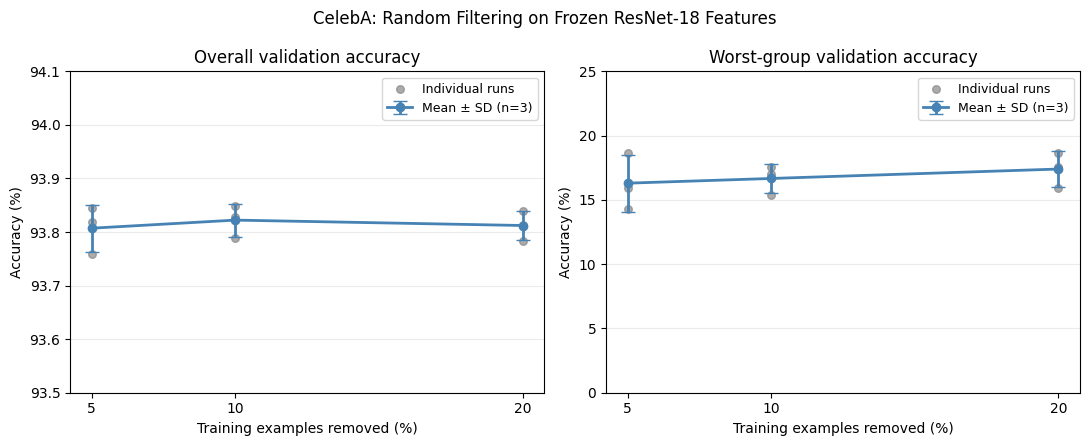

Figure saved to: results\figures\random_filtering_performance.png


In [7]:
import matplotlib.pyplot as plt

results_df = pd.read_csv(
    METRICS_DIR / "random_filtering_results.csv"
)

FIGURE_DIR = Path("results/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use("default")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

panels = [
    ("Overall Accuracy (%)", "Overall validation accuracy", (93.5, 94.1)),
    ("Worst-Group Accuracy (%)", "Worst-group validation accuracy", (0, 25)),
]

for ax, (metric, title, limits) in zip(axes, panels):
    stats = results_df.groupby("Filter Rate (%)")[metric].agg(
        ["mean", "std"]
    )

    ax.scatter(
        results_df["Filter Rate (%)"],
        results_df[metric],
        color="gray",
        alpha=0.65,
        s=30,
        label="Individual runs",
        zorder=2,
    )

    ax.errorbar(
        stats.index,
        stats["mean"],
        yerr=stats["std"],
        fmt="o-",
        capsize=5,
        linewidth=2,
        color="steelblue",
        label="Mean ± SD (n=3)",
        zorder=3,
    )

    ax.set_title(title)
    ax.set_xlabel("Training examples removed (%)")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xticks([5, 10, 20])
    ax.set_ylim(*limits)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle("CelebA: Random Filtering on Frozen ResNet-18 Features")
fig.tight_layout()

save_path = FIGURE_DIR / "random_filtering_performance.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {save_path}")

## 6. Group Accuracy and Retention

Compare group-level validation accuracy and training-sample retention.
Error bars show standard deviation across three seeds.

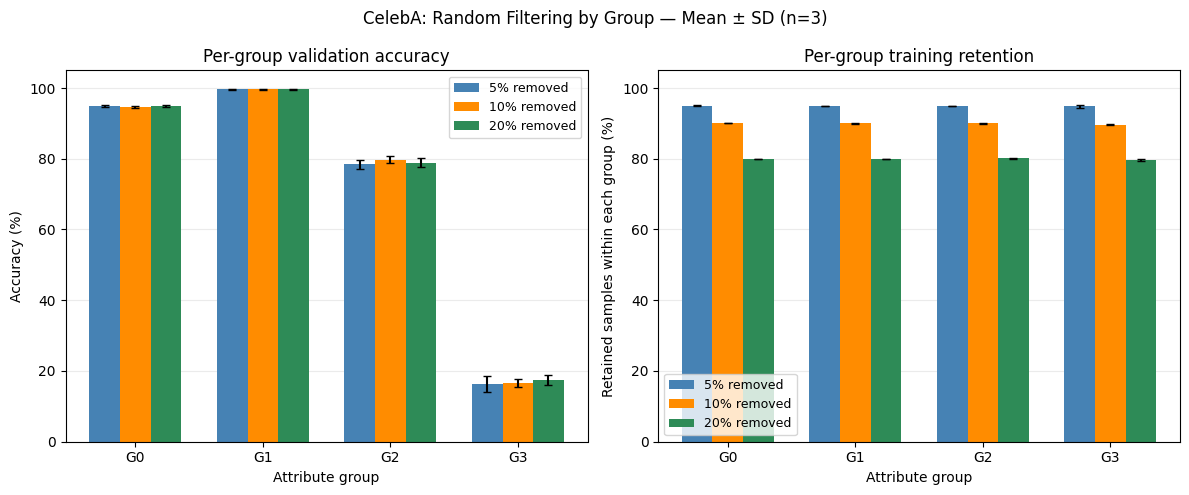

Figure saved to: results\figures\random_filtering_group_analysis.png


In [8]:
retention_df = pd.read_csv(
    METRICS_DIR / "random_filtering_group_retention.csv"
)

accuracy_long = results_df.melt(
    id_vars=["Filter Rate (%)", "Training Seed"],
    value_vars=[f"G{g} Accuracy (%)" for g in range(4)],
    var_name="Group",
    value_name="Accuracy (%)",
)
accuracy_long["Group"] = (
    accuracy_long["Group"].str.extract(r"G(\d)")[0].astype(int)
)

accuracy_stats = (
    accuracy_long.groupby(["Filter Rate (%)", "Group"])["Accuracy (%)"]
    .agg(["mean", "std"])
    .reset_index()
)

retention_stats = (
    retention_df.groupby(["Filter Rate (%)", "Group"])["Retention Rate (%)"]
    .agg(["mean", "std"])
    .reset_index()
)

accuracy_stats.to_csv(
    METRICS_DIR / "random_filtering_group_accuracy_summary.csv",
    index=False,
)
retention_stats.to_csv(
    METRICS_DIR / "random_filtering_group_retention_summary.csv",
    index=False,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = np.arange(4)
width = 0.24
colors = ["steelblue", "darkorange", "seagreen"]

for i, (rate_pct, color) in enumerate(zip([5, 10, 20], colors)):
    positions = x + (i - 1) * width

    for ax, stats in zip(axes, [accuracy_stats, retention_stats]):
        subset = (
            stats[stats["Filter Rate (%)"] == rate_pct]
            .set_index("Group")
            .reindex(range(4))
        )

        ax.bar(
            positions,
            subset["mean"],
            width,
            yerr=subset["std"],
            capsize=3,
            color=color,
            label=f"{rate_pct}% removed",
        )

axes[0].set_title("Per-group validation accuracy")
axes[0].set_ylabel("Accuracy (%)")

axes[1].set_title("Per-group training retention")
axes[1].set_ylabel("Retained samples within each group (%)")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(["G0", "G1", "G2", "G3"])
    ax.set_xlabel("Attribute group")
    ax.set_ylim(0, 105)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle("CelebA: Random Filtering by Group — Mean ± SD (n=3)")
fig.tight_layout()

save_path = FIGURE_DIR / "random_filtering_group_analysis.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {save_path}")

## 7. Training and Validation Loss

Show mean loss and standard deviation across three seeds at each epoch.
Final checkpoints are selected separately for each run by validation loss.

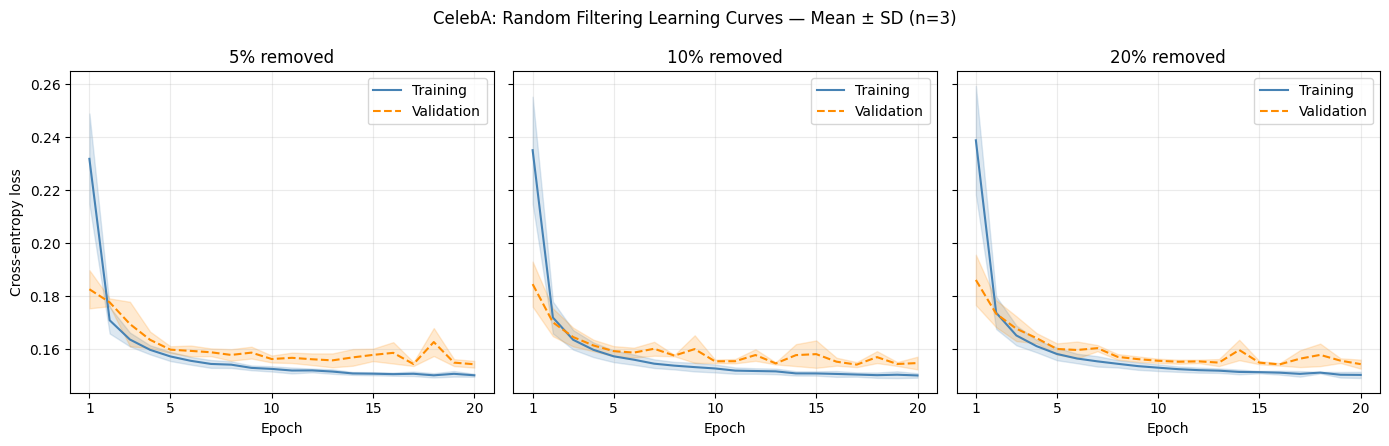

Figure saved to: results\figures\random_filtering_training_curves.png


In [9]:
history_frames = []

for rate_pct in [5, 10, 20]:
    for seed in SEEDS:
        path = METRICS_DIR / (
            f"random_{rate_pct}pct_select{seed}_train{seed}_history.csv"
        )

        history = pd.read_csv(path)
        assert history["epoch"].tolist() == list(range(1, EPOCHS + 1))

        history["Filter Rate (%)"] = rate_pct
        history["Selection Seed"] = seed
        history["Training Seed"] = seed
        history_frames.append(history)

all_history = pd.concat(history_frames, ignore_index=True)
all_history.to_csv(
    METRICS_DIR / "random_filtering_training_history.csv",
    index=False,
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)

for ax, rate_pct in zip(axes, [5, 10, 20]):
    subset = all_history[all_history["Filter Rate (%)"] == rate_pct]

    for column, label, color, linestyle in [
        ("train_loss", "Training", "steelblue", "-"),
        ("val_loss", "Validation", "darkorange", "--"),
    ]:
        stats = subset.groupby("epoch")[column].agg(["mean", "std"])

        epochs = stats.index.to_numpy()
        mean = stats["mean"].to_numpy()
        std = stats["std"].to_numpy()

        ax.plot(
            epochs, mean,
            label=label, color=color, linestyle=linestyle,
        )
        ax.fill_between(
            epochs, mean - std, mean + std,
            color=color, alpha=0.18,
        )

    ax.set_title(f"{rate_pct}% removed")
    ax.set_xlabel("Epoch")
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("Cross-entropy loss")
fig.suptitle("CelebA: Random Filtering Learning Curves — Mean ± SD (n=3)")
fig.tight_layout()

save_path = FIGURE_DIR / "random_filtering_training_curves.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {save_path}")

## 8. Comparison with Team Reference Results

Compare local random-filtering runs with saved team ERM and
EPIC-inspired results. All metrics use the validation split.
Execution environments differ, so comparisons are descriptive.

In [10]:
metric_cols = [
    "Overall Accuracy (%)",
    "Worst-Group Accuracy (%)",
]

# Local random-filtering results.
local_random = results_df.rename(
    columns={"Training Seed": "Seed"}
).copy()
local_random["Method"] = "Random"
local_random["Source"] = "Local reproduction"

# Team EPIC-inspired results.
team_filtering = pd.read_csv(
    METRICS_DIR / "epic_filtering_sensitivity.csv"
)
team_epic = team_filtering[
    team_filtering["Method"] == "Isolation"
].copy()
team_epic["Method"] = "EPIC-inspired"
team_epic["Source"] = "Team reference"

# Team three-seed ERM baseline.
team_multiseed = pd.read_csv(
    METRICS_DIR / "epic_multiseed_10pct.csv"
)
team_erm = team_multiseed[
    team_multiseed["Method"] == "ERM"
].copy()
team_erm["Filter Rate (%)"] = 0
team_erm["Source"] = "Team reference"

columns = ["Method", "Source", "Filter Rate (%)", "Seed", *metric_cols]
comparison_runs = pd.concat(
    [local_random[columns], team_epic[columns], team_erm[columns]],
    ignore_index=True,
)
comparison_runs["Split"] = "validation"

keys = ["Method", "Source", "Filter Rate (%)"]
assert not comparison_runs.duplicated(keys + ["Seed"]).any()
for _, subset in comparison_runs.groupby(keys):
    assert len(subset) == 3
    assert set(subset["Seed"]) == set(SEEDS)

comparison_summary = (
    comparison_runs.groupby(keys)[metric_cols]
    .agg(["mean", "std"])
)
comparison_summary.columns = [
    f"{metric} {stat}"
    for metric, stat in comparison_summary.columns
]
comparison_summary = comparison_summary.reset_index()

comparison_runs.to_csv(
    METRICS_DIR / "random_filtering_method_comparison_runs.csv",
    index=False,
)
comparison_summary.to_csv(
    METRICS_DIR / "random_filtering_method_comparison_summary.csv",
    index=False,
)

print(comparison_summary.round(3).to_string(index=False))

       Method             Source  Filter Rate (%)  Overall Accuracy (%) mean  Overall Accuracy (%) std  Worst-Group Accuracy (%) mean  Worst-Group Accuracy (%) std
EPIC-inspired     Team reference                5                     93.824                     0.033                         14.103                         0.317
EPIC-inspired     Team reference               10                     93.878                     0.054                         15.751                         1.586
EPIC-inspired     Team reference               20                     93.787                     0.036                         15.018                         0.634
          ERM     Team reference                0                     93.811                     0.008                         15.751                         0.317
       Random Local reproduction                5                     93.807                     0.044                         16.300                         2.221
       Random Lo

## 9. Method Comparison

Error bars show standard deviation across three seeds.
ERM and EPIC-inspired results are team references; Random results
are local reproductions. ERM uses the full training set.

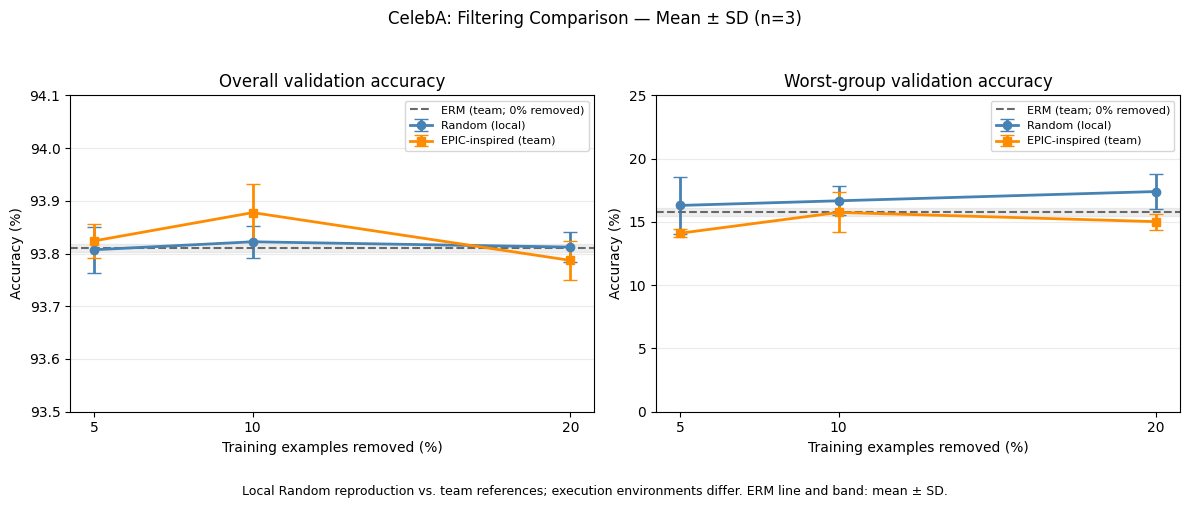

Figure saved to: results\figures\random_filtering_method_comparison.png


In [11]:
comparison_summary = pd.read_csv(
    METRICS_DIR / "random_filtering_method_comparison_summary.csv"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

panels = [
    ("Overall Accuracy (%)", "Overall validation accuracy", (93.5, 94.1)),
    ("Worst-Group Accuracy (%)", "Worst-group validation accuracy", (0, 25)),
]

erm = comparison_summary[
    comparison_summary["Method"] == "ERM"
].iloc[0]

for ax, (metric, title, limits) in zip(axes, panels):
    for method, label, color, marker in [
        ("Random", "Random (local)", "steelblue", "o"),
        ("EPIC-inspired", "EPIC-inspired (team)", "darkorange", "s"),
    ]:
        subset = comparison_summary[
            comparison_summary["Method"] == method
        ].sort_values("Filter Rate (%)")

        ax.errorbar(
            subset["Filter Rate (%)"],
            subset[f"{metric} mean"],
            yerr=subset[f"{metric} std"],
            label=label,
            color=color,
            marker=marker,
            linestyle="-",
            linewidth=2,
            capsize=5,
        )

    erm_mean = erm[f"{metric} mean"]
    erm_std = erm[f"{metric} std"]

    ax.axhline(
        erm_mean,
        color="dimgray",
        linestyle="--",
        label="ERM (team; 0% removed)",
    )
    ax.axhspan(
        erm_mean - erm_std,
        erm_mean + erm_std,
        color="gray",
        alpha=0.12,
    )

    ax.set_title(title)
    ax.set_xlabel("Training examples removed (%)")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xticks([5, 10, 20])
    ax.set_ylim(*limits)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle("CelebA: Filtering Comparison — Mean ± SD (n=3)")
fig.text(
    0.5, 0.01,
    "Local Random reproduction vs. team references; "
    "execution environments differ. ERM line and band: mean ± SD.",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0.06, 1, 0.95])

save_path = FIGURE_DIR / "random_filtering_method_comparison.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {save_path}")

## 10. Results and Limitations

Random filtering achieved validation overall accuracies of
93.807%, 93.822%, and 93.812% at removal rates of 5%, 10%, and 20%.
Corresponding worst-group accuracies were 16.300 ± 2.221%,
16.667 ± 1.144%, and 17.399 ± 1.383% across three seeds.

Group retention remained close to the nominal retention rates.
G3 remained the worst-performing group despite high overall accuracy.

Mean worst-group accuracy exceeded the team EPIC-inspired references
by 2.20, 0.92, and 2.38 percentage points, respectively.
These descriptive comparisons use different execution environments
and do not establish statistical significance or causality.

Selection and training seeds were paired numerically, so their
individual contributions to variability were not isolated.
Reported runtime includes classifier training and validation,
excluding one-time feature extraction and data preparation.
The test set remains reserved for final evaluation.